# Phase 2: Probability and Probability Distributions
**NHANES 2021–2023: sleep duration, physical activity, HbA1c, and BMI among U.S. adults** (Track A)

The analysis code lives in `src/` (`events.py`, `07_probability_events.py`, `08_distributions.py`, `09_build_phase2_report.py`). This notebook runs those scripts, displays their tables and figures, and records the reasoning. Run all cells from top to bottom. The full write-up is `reports/phase2/phase2_report.pdf`.

### Where to find each task

| Task | Section |
|---|---|
| 1 Events and random variables | 1 |
| 2 Marginal and joint probabilities | 2 |
| 3 Conditional probability; A.1 subgroup probabilities | 3 |
| 4 Independence | 4 |
| 5 Binomial model; A.2 binomial for a count | 5 |
| 6 Normal distribution; A.3 shape of a health measurement | 6 |
| 7 Expectation and variance | 7 |
| 8 Two random variables and covariance | 8 |
| 9 Bayes' theorem | 9 |
| A.4 Role of sampling weights in empirical probability | 10 |

In [15]:
import io
import runpy
import sys
from contextlib import redirect_stdout
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
TABLES = ROOT / "reports" / "phase2" / "tables"
FIGS = ROOT / "figures" / "phase2"
sys.path.insert(0, str(SRC))
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)


def run_step(name):
    """Run one script from src/ exactly as `python src/<name>.py` would, silently."""
    buffer = io.StringIO()
    with redirect_stdout(buffer):
        runpy.run_path(str(SRC / f"{name}.py"), run_name="__main__")


def show_table(name, digits=4):
    display(pd.read_csv(TABLES / f"{name}.csv").round(digits))


def show_figure(name, width=640):
    display(Image(filename=str(FIGS / name), width=width))


run_step("07_probability_events")
run_step("08_distributions")
print("Tables written to", TABLES)
print("Figures written to", FIGS)

Tables written to C:\Users\Acer\PycharmProjects\stat-project\reports\phase2\tables
Figures written to C:\Users\Acer\PycharmProjects\stat-project\figures\phase2


## 1. Events and random variables (task 1)

The analytic sample is the 5,490 adults of Phase 1. Probabilities are empirical relative frequencies; a weighted version uses the phlebotomy weight `WTPH2YR`.

- **B**: diabetes-range HbA1c (`LBXGH` ≥ 6.5%), the commonly used laboratory cutoff for diabetes.
- **A**: short sleep (average sleep < 7 h/day), below the commonly recommended 7–9 hours.
- Other events: long sleep (≥ 9 h), no leisure-time activity (0 min/week), obesity (BMI ≥ 30), age ≥ 60, and self-reported diagnosed diabetes (**D**).
- **Y** = HbA1c of a randomly chosen adult (continuous); **I_B** = indicator of B (Bernoulli); **K** = number of adults with B among 90 random adults (binomial under simple random sampling).

In [16]:
show_table("events_definition")

,event,definition,n_events,p_unweighted,p_weighted
0,high_hba1c,HbA1c >= 6.5 % (diabetes-range value),682,0.1242,0.1044
1,short_sleep,Average sleep < 7 hours per day,1107,0.2016,0.1929
2,long_sleep,Average sleep >= 9 hours per day,1131,0.2060,0.1924
3,inactive,No leisure-time moderate or vigorous activity ...,1008,0.1836,0.1637
4,obesity,BMI >= 30 kg/m^2,2251,0.4100,0.4019
5,age_60plus,Age >= 60 years,2516,0.4583,0.3096
6,diabetes_dx,Self-reported diagnosed diabetes (DIQ010 = 1),768,0.1399,0.1152


## 2. Marginal and joint probabilities (task 2)

If A (short sleep) and B (high HbA1c) were independent, we would expect P(A and B) = P(A) × P(B).

In [17]:
show_table("joint_short_sleep_high_hba1c")

,cell,n,joint_probability,expected_if_independent
0,A and B,153,0.0279,0.0250
1,A and not B,954,0.1738,0.1766
2,not A and B,529,0.0964,0.0992
3,not A and not B,3854,0.7020,0.6992
4,P(A) marginal,1107,0.2016,NaN
5,P(B) marginal,682,0.1242,NaN


**Result.** P(A) = 20.2% and P(B) = 12.4%. Both events occur together in 2.79% of adults (153 adults), versus 2.50% expected under independence.

## 3. Conditional probabilities and subgroups (task 3, A.1)

Conditioning on a group restricts attention to its members and recomputes the probability within the group: P(B | G) = P(B and G) / P(G).

,given,n,p_b_given_unweighted,ratio_to_overall,p_b_given_weighted,ratio_to_overall_weighted
0,short sleep (<7 h),1107,0.1382,1.1126,0.1192,1.1411
1,recommended sleep (7 to <9 h),3252,0.1021,0.8218,0.0876,0.8386
2,long sleep (>=9 h),1131,0.1742,1.4021,0.1435,1.3742
3,no leisure-time activity,1008,0.2173,1.7489,0.1884,1.8042
4,some leisure-time activity,4482,0.1033,0.8316,0.0880,0.8426
5,obesity (BMI >= 30),2251,0.1959,1.5771,0.1757,1.6821
6,no obesity (BMI < 30),3239,0.0744,0.5990,0.0566,0.5416
7,age >= 60,2516,0.1745,1.4046,0.1734,1.6602
8,age < 60,2974,0.0817,0.6577,0.0735,0.7039


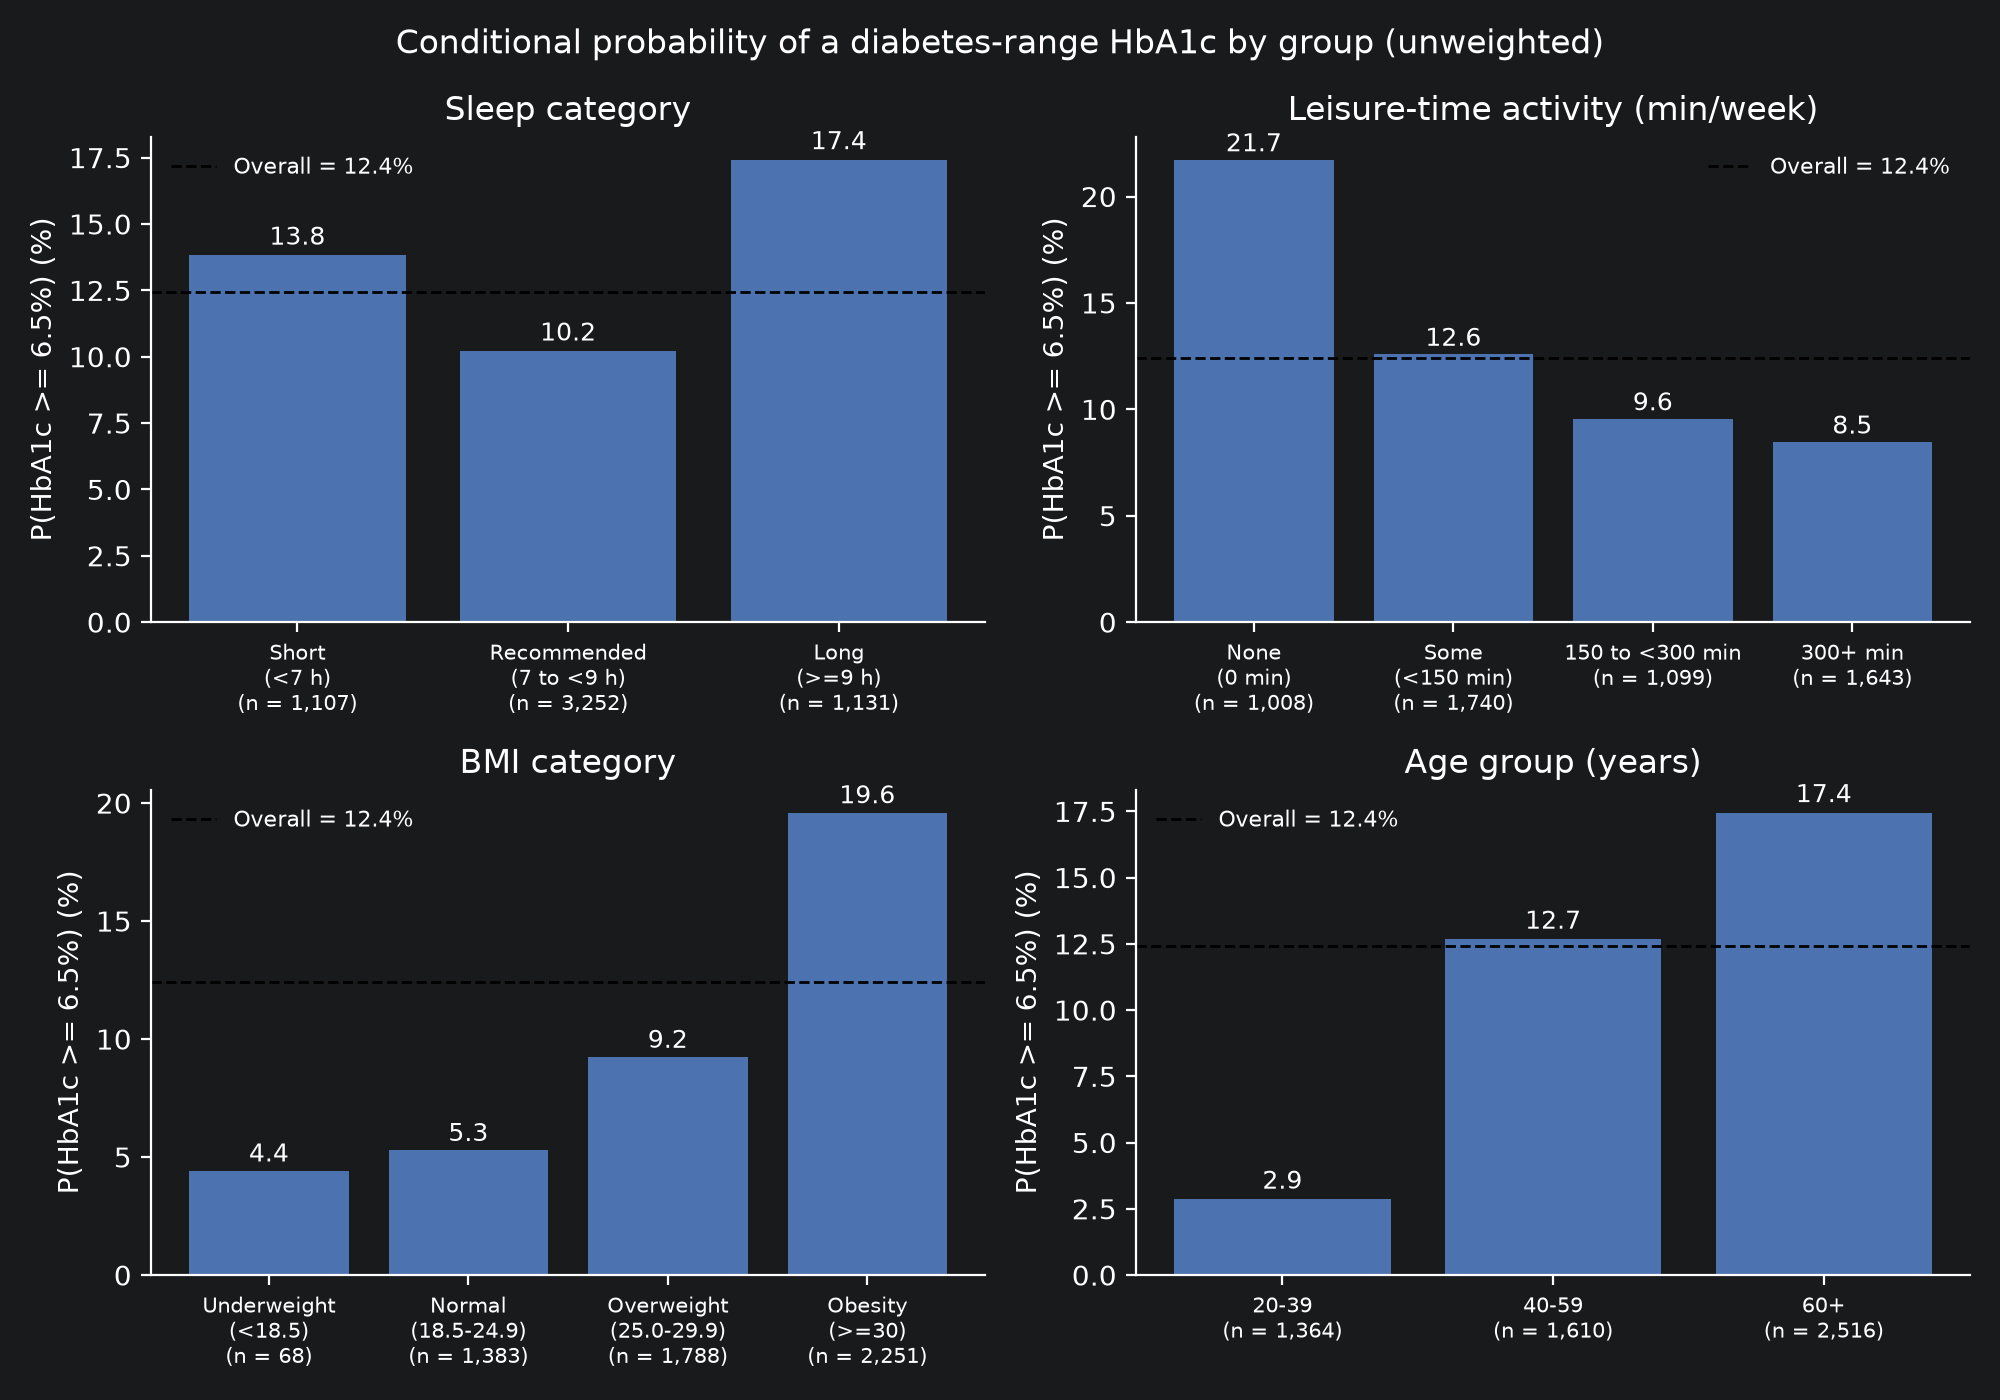

In [18]:
show_table("conditional_probabilities")
show_figure("p2_fig1_conditional_probabilities.png", width=720)

In [19]:
show_table("subgroup_probabilities")

,variable,group,n,n_events,p_unweighted,p_weighted,diff_from_overall_pp
0,sex,Female,3016,333,0.1104,0.0927,-1.3815
1,sex,Male,2474,349,0.1411,0.1166,1.6841
2,age_group,20-39,1364,39,0.0286,0.0300,-9.5633
3,age_group,40-59,1610,204,0.1267,0.1181,0.2482
4,age_group,60+,2516,439,0.1745,0.1734,5.0257
5,race_eth,Mexican American,369,67,0.1816,0.1444,5.7346
6,race_eth,Non-Hispanic Asian,307,35,0.1140,0.0770,-1.0219
7,race_eth,Non-Hispanic Black,620,105,0.1694,0.1569,4.5129
8,race_eth,Non-Hispanic White,3294,351,0.1066,0.0923,-1.7668
9,race_eth,Other / multiracial,345,52,0.1507,0.1313,2.6499


**Interpretation.** Overall P(B) = 12.4%, but P(B | no leisure-time activity) = 21.7% (1.75 times the overall probability), P(B | obesity) = 19.6% versus 7.4% without obesity, and P(B | age 60+) = 17.4%. Sleep shows a U-shaped pattern: 10.2% with recommended sleep versus 13.8% with short and 17.4% with long sleep. Subgroup differences are described only; no tests are performed in this phase.

## 4. Independence (task 4)

A ratio of the observed joint probability to P(A) × P(B) near 1 is consistent with independence. No formal test is performed in this phase.

In [20]:
show_table("independence_check")
show_table("short_sleep_by_age")

,event_A,P(A and B),P(A) x P(B),joint / expected,P(B|A),P(B),P(B|A) - P(B)
0,short_sleep,0.0279,0.0250,1.1126,0.1382,0.1242,0.0140
1,long_sleep,0.0359,0.0256,1.4021,0.1742,0.1242,0.0500
2,inactive,0.0399,0.0228,1.7489,0.2173,0.1242,0.0930
3,obesity,0.0803,0.0509,1.5771,0.1959,0.1242,0.0717
4,age_60plus,0.0800,0.0569,1.4046,0.1745,0.1242,0.0503


,age_group,n,P(short sleep),P(B | short sleep),P(B | not short sleep)
0,20-39,1364,0.1796,0.0408,0.0259
1,40-59,1610,0.2360,0.1447,0.1211
2,60+,2516,0.1916,0.1826,0.1726


**Interpretation.** For short sleep the ratio is 1.11 and P(B | A) differs from P(B) by only 1.4 percentage points, so the data appear roughly consistent with independence. For long sleep, inactivity, obesity, and age 60+ the ratios are 1.40–1.75, which is not consistent with independence. "Consistent" does not mean "proven independent": sampling variability could hide a weak association, and within every age group the probability of B is slightly higher among short sleepers.

## 5. Binomial model for a count (task 5, A.2)

A binomial model requires a fixed number of trials, two outcomes, independent trials, and a common probability. We compare the number of adults with B in equal-sized subsamples of 90 adults with Bin(90, 0.124): (a) simple random subsamples of the analytic sample, and (b) random subsamples taken within each of the 30 design clusters (masked stratum × PSU).

,scenario,mean_of_counts,variance_of_counts,binomial_mean,binomial_variance,hypergeometric_variance,variance_ratio_to_binomial
0,"Random subsamples of 90 adults (10,000 draws)",11.0868,9.6620,11.1803,9.7914,9.6327,0.9868
1,Subsamples of 90 adults within each of 30 desi...,11.5779,17.3577,11.1803,9.7914,NaN,1.7727


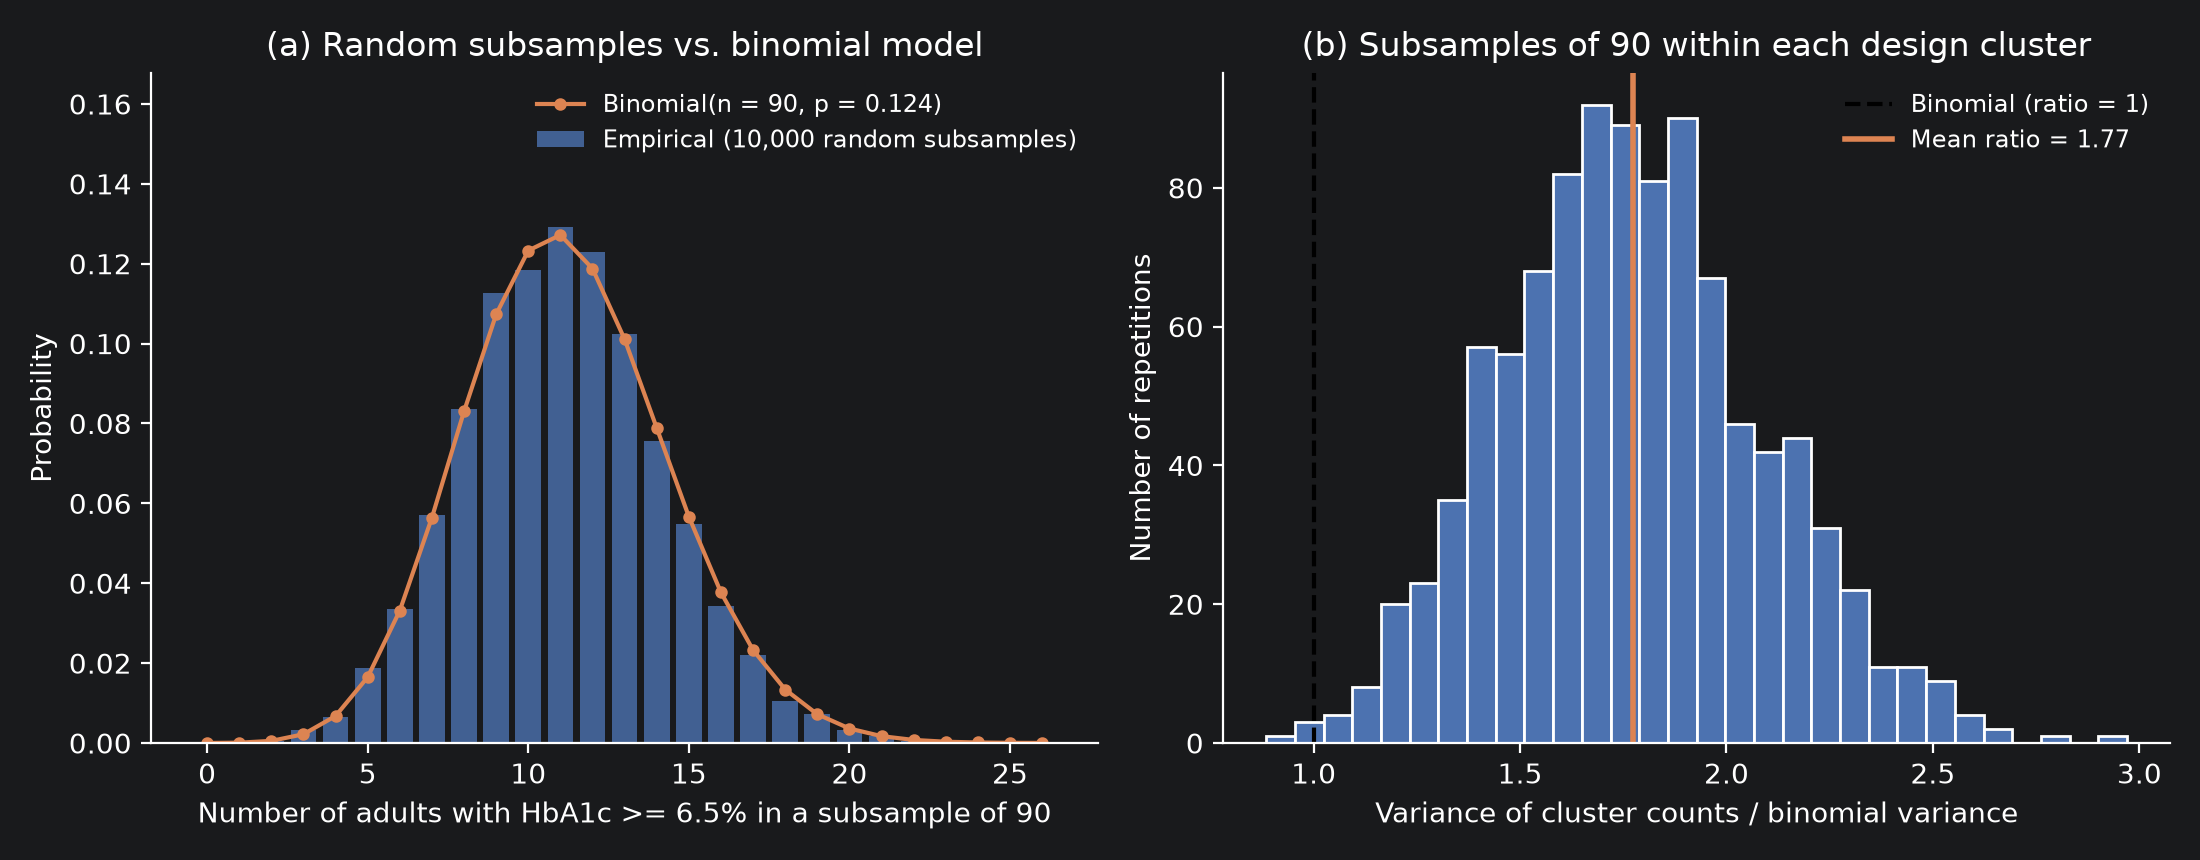

In [21]:
show_table("binomial_summary")
show_figure("p2_fig3_binomial_vs_empirical.png", width=800)

In [22]:
clusters = pd.read_csv(TABLES / "cluster_proportions.csv")
print("Cluster proportions with B: min = %.3f, max = %.3f, SD = %.3f"
      % (clusters["p"].min(), clusters["p"].max(), clusters["p"].std()))

Cluster proportions with B: min = 0.045, max = 0.216, SD = 0.039


**Interpretation.** For random subsamples the variance of the count is 9.66 versus 9.79 for the binomial (ratio 0.99; the small shortfall is the finite-population effect), so the model fits. Within design clusters the variance is on average 1.77 times larger (over-dispersion) because the probability differs between clusters (4.5% to 21.6%). The independence and common-probability assumptions therefore fail for the survey as a whole, which is why Phase 3 uses design-aware methods.

## 6. Normal distribution and the shape of health measurements (task 6, A.3)

We examine sleep, BMI, and HbA1c with histograms and normal densities, normal Q-Q plots, skewness, excess kurtosis, and the share of values within 1, 2, and 3 SD (68.3%, 95.4%, 99.7% under normality). A normality test alone would not be informative with 5,490 observations.

In [23]:
show_table("normal_approximation", digits=3)

,variable,scale,n,mean,sd,skewness,excess_kurtosis,pct_within_1sd,pct_within_2sd,pct_within_3sd,n_beyond_3sd,qq_correlation
0,Sleep (h/day),raw,5490.0,7.853,1.467,-0.160,2.105,75.501,94.718,98.561,79.0,0.985
1,BMI (kg/m^2),raw,5490.0,29.830,7.270,1.226,2.479,73.406,95.592,98.670,73.0,0.964
2,BMI (kg/m^2),natural log,5490.0,3.368,0.228,0.437,0.251,68.871,95.501,99.508,27.0,0.994
3,HbA1c (%),raw,5490.0,5.783,1.091,3.564,18.066,89.308,95.446,97.468,139.0,0.816
4,HbA1c (%),natural log,5490.0,1.742,0.153,2.301,8.002,84.809,94.936,97.414,142.0,0.894
5,Normal distribution (reference),NaN,NaN,NaN,NaN,0.000,0.000,68.269,95.450,99.730,NaN,1.000


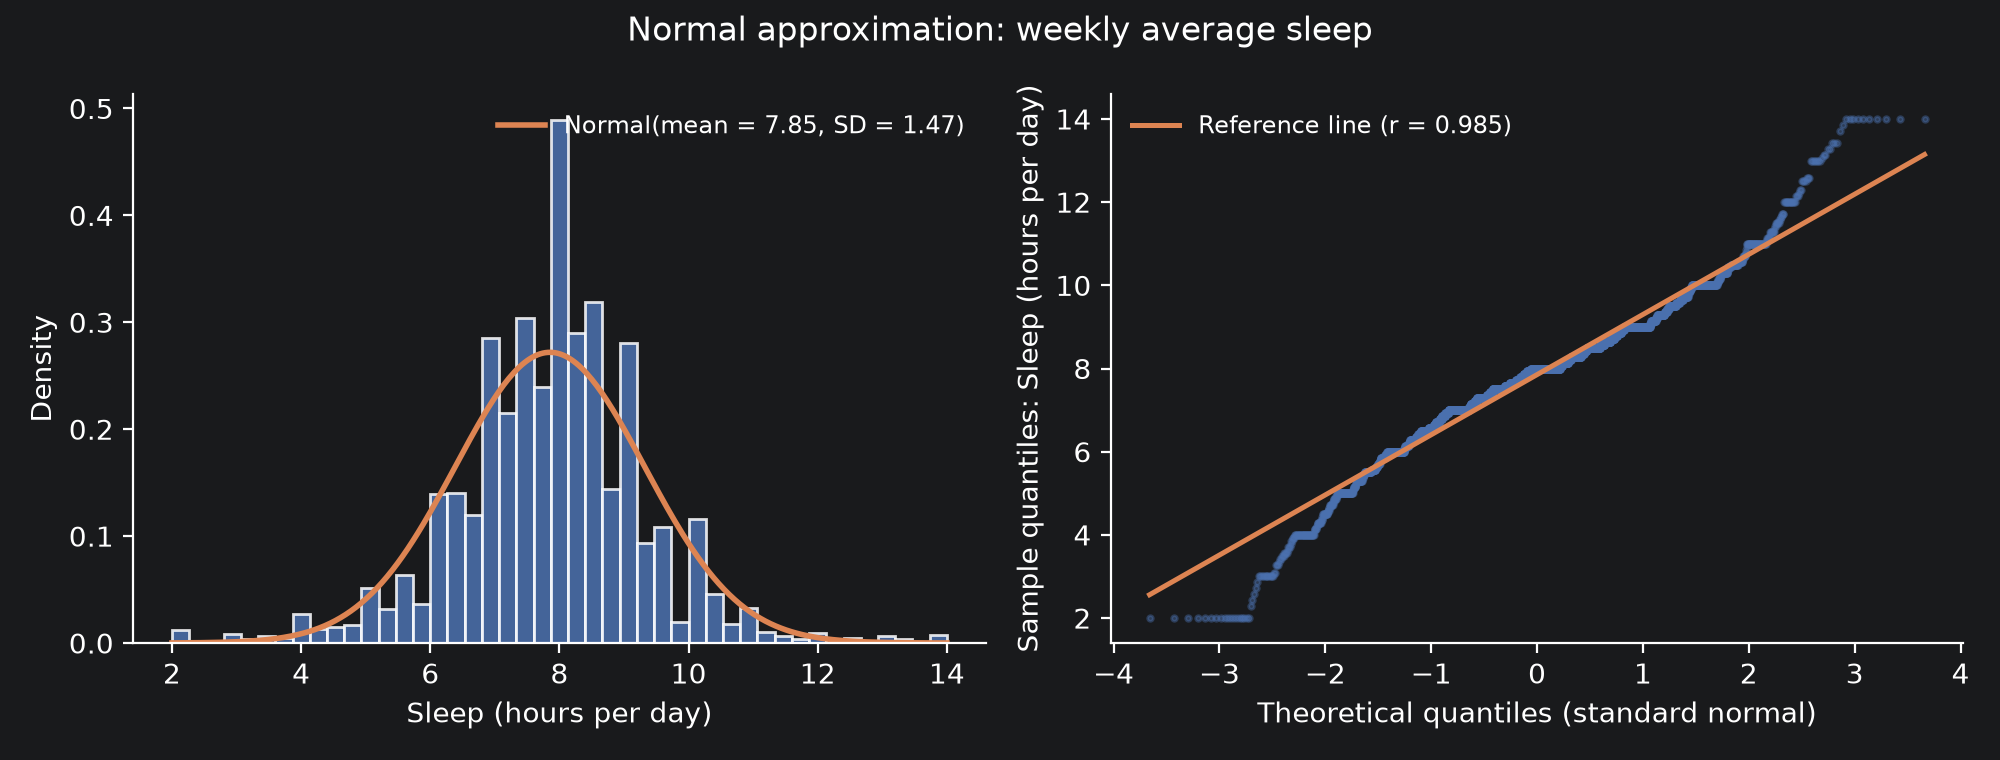

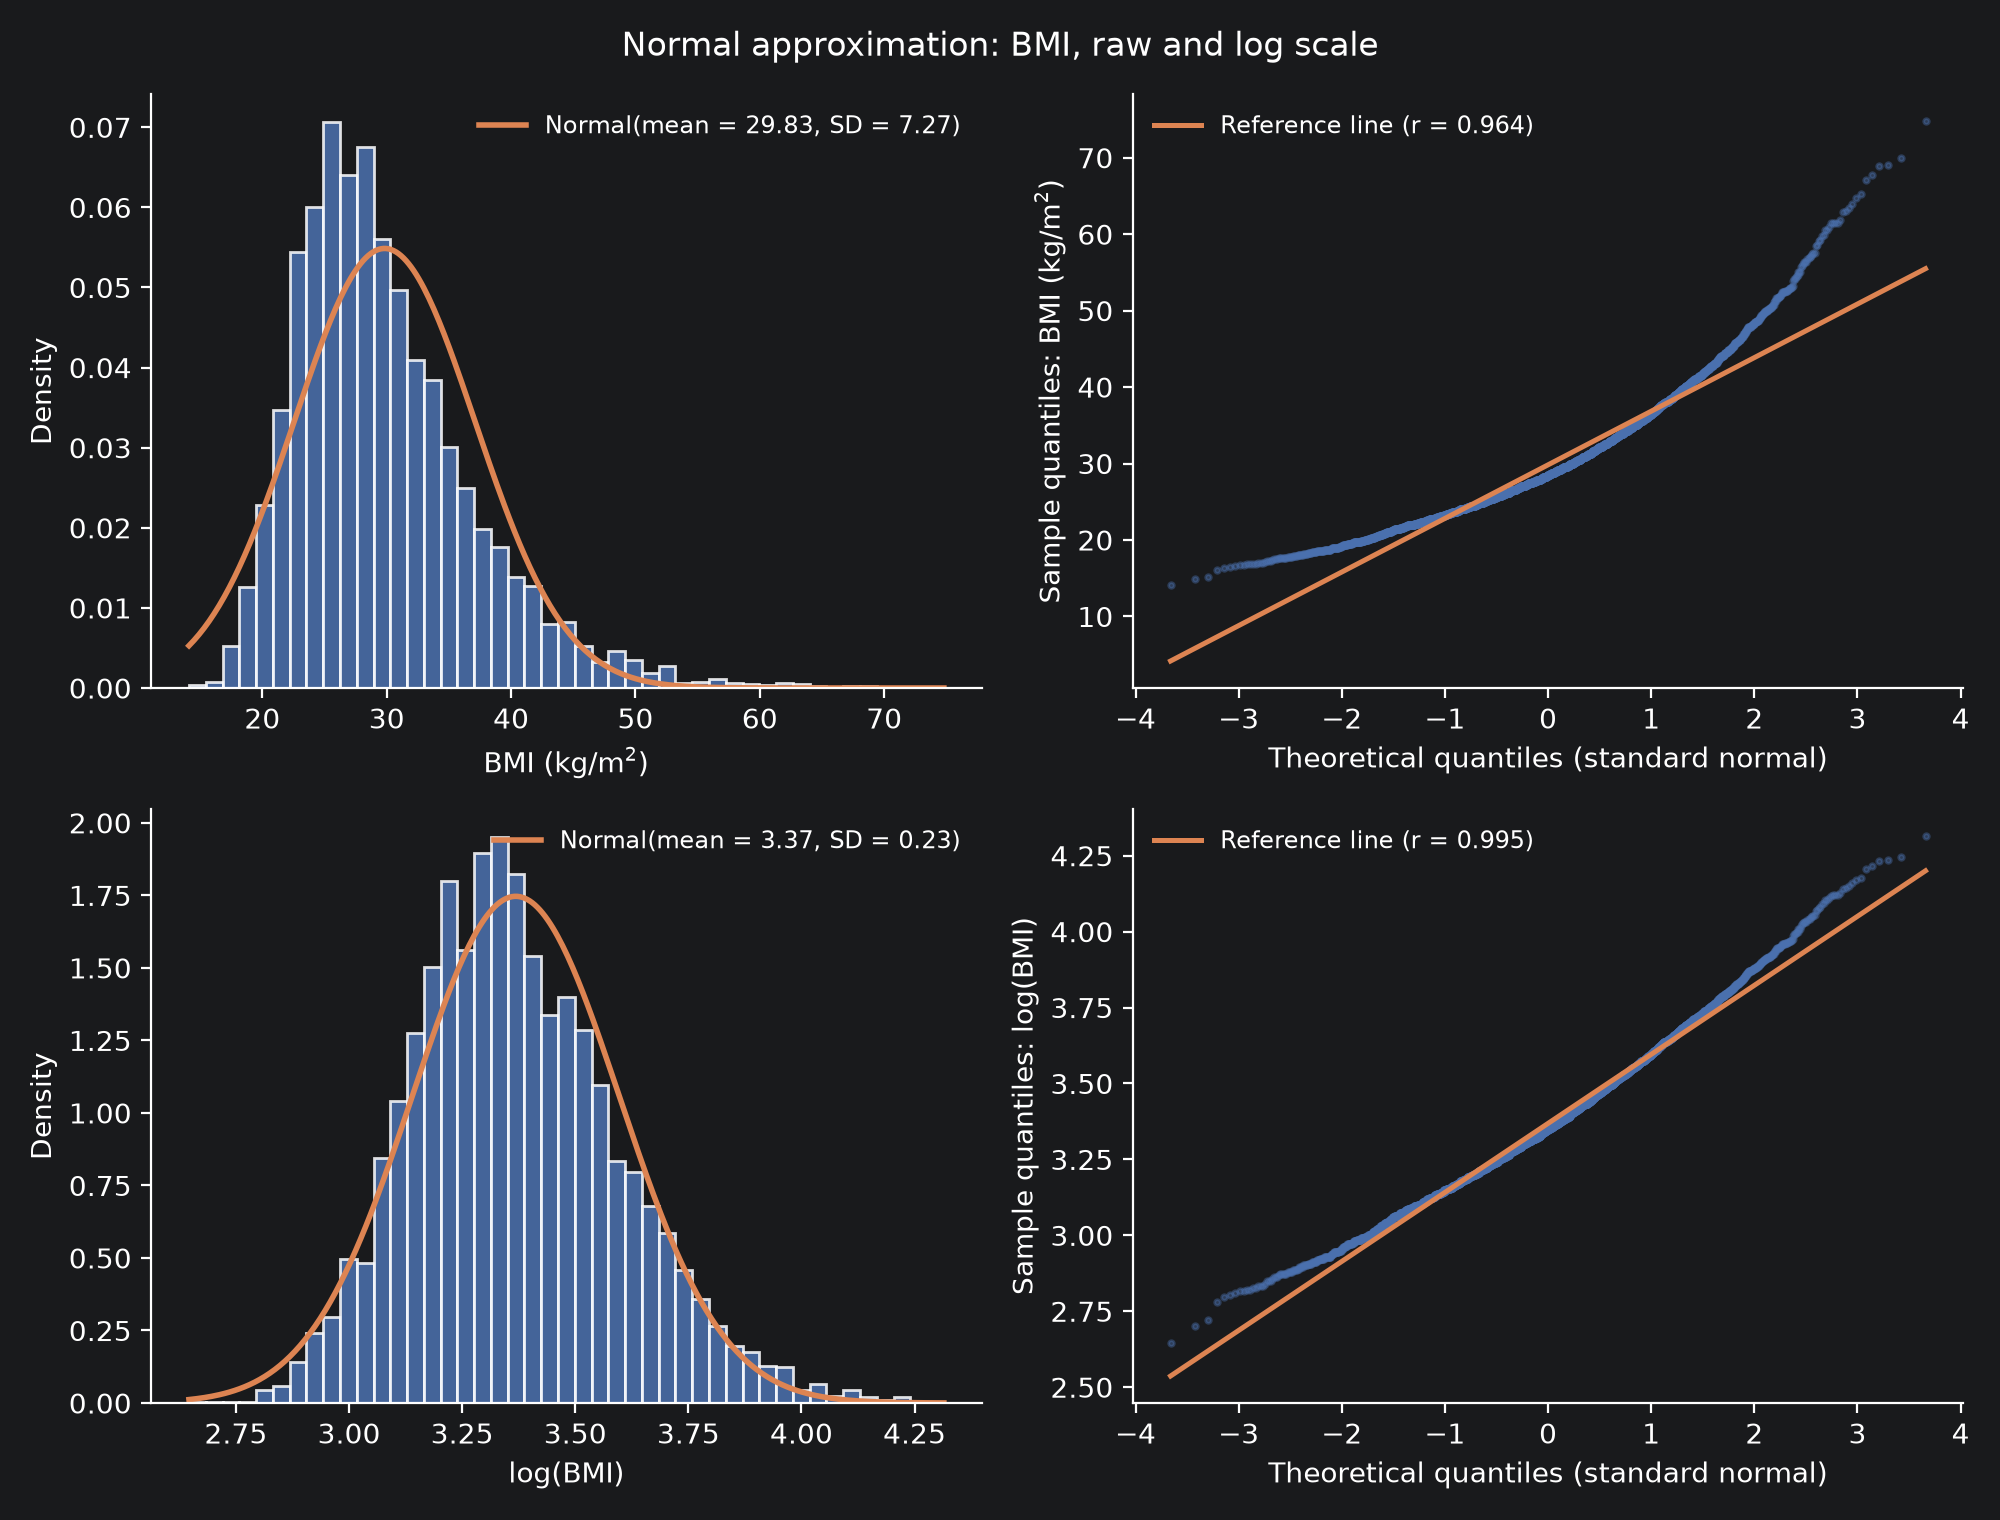

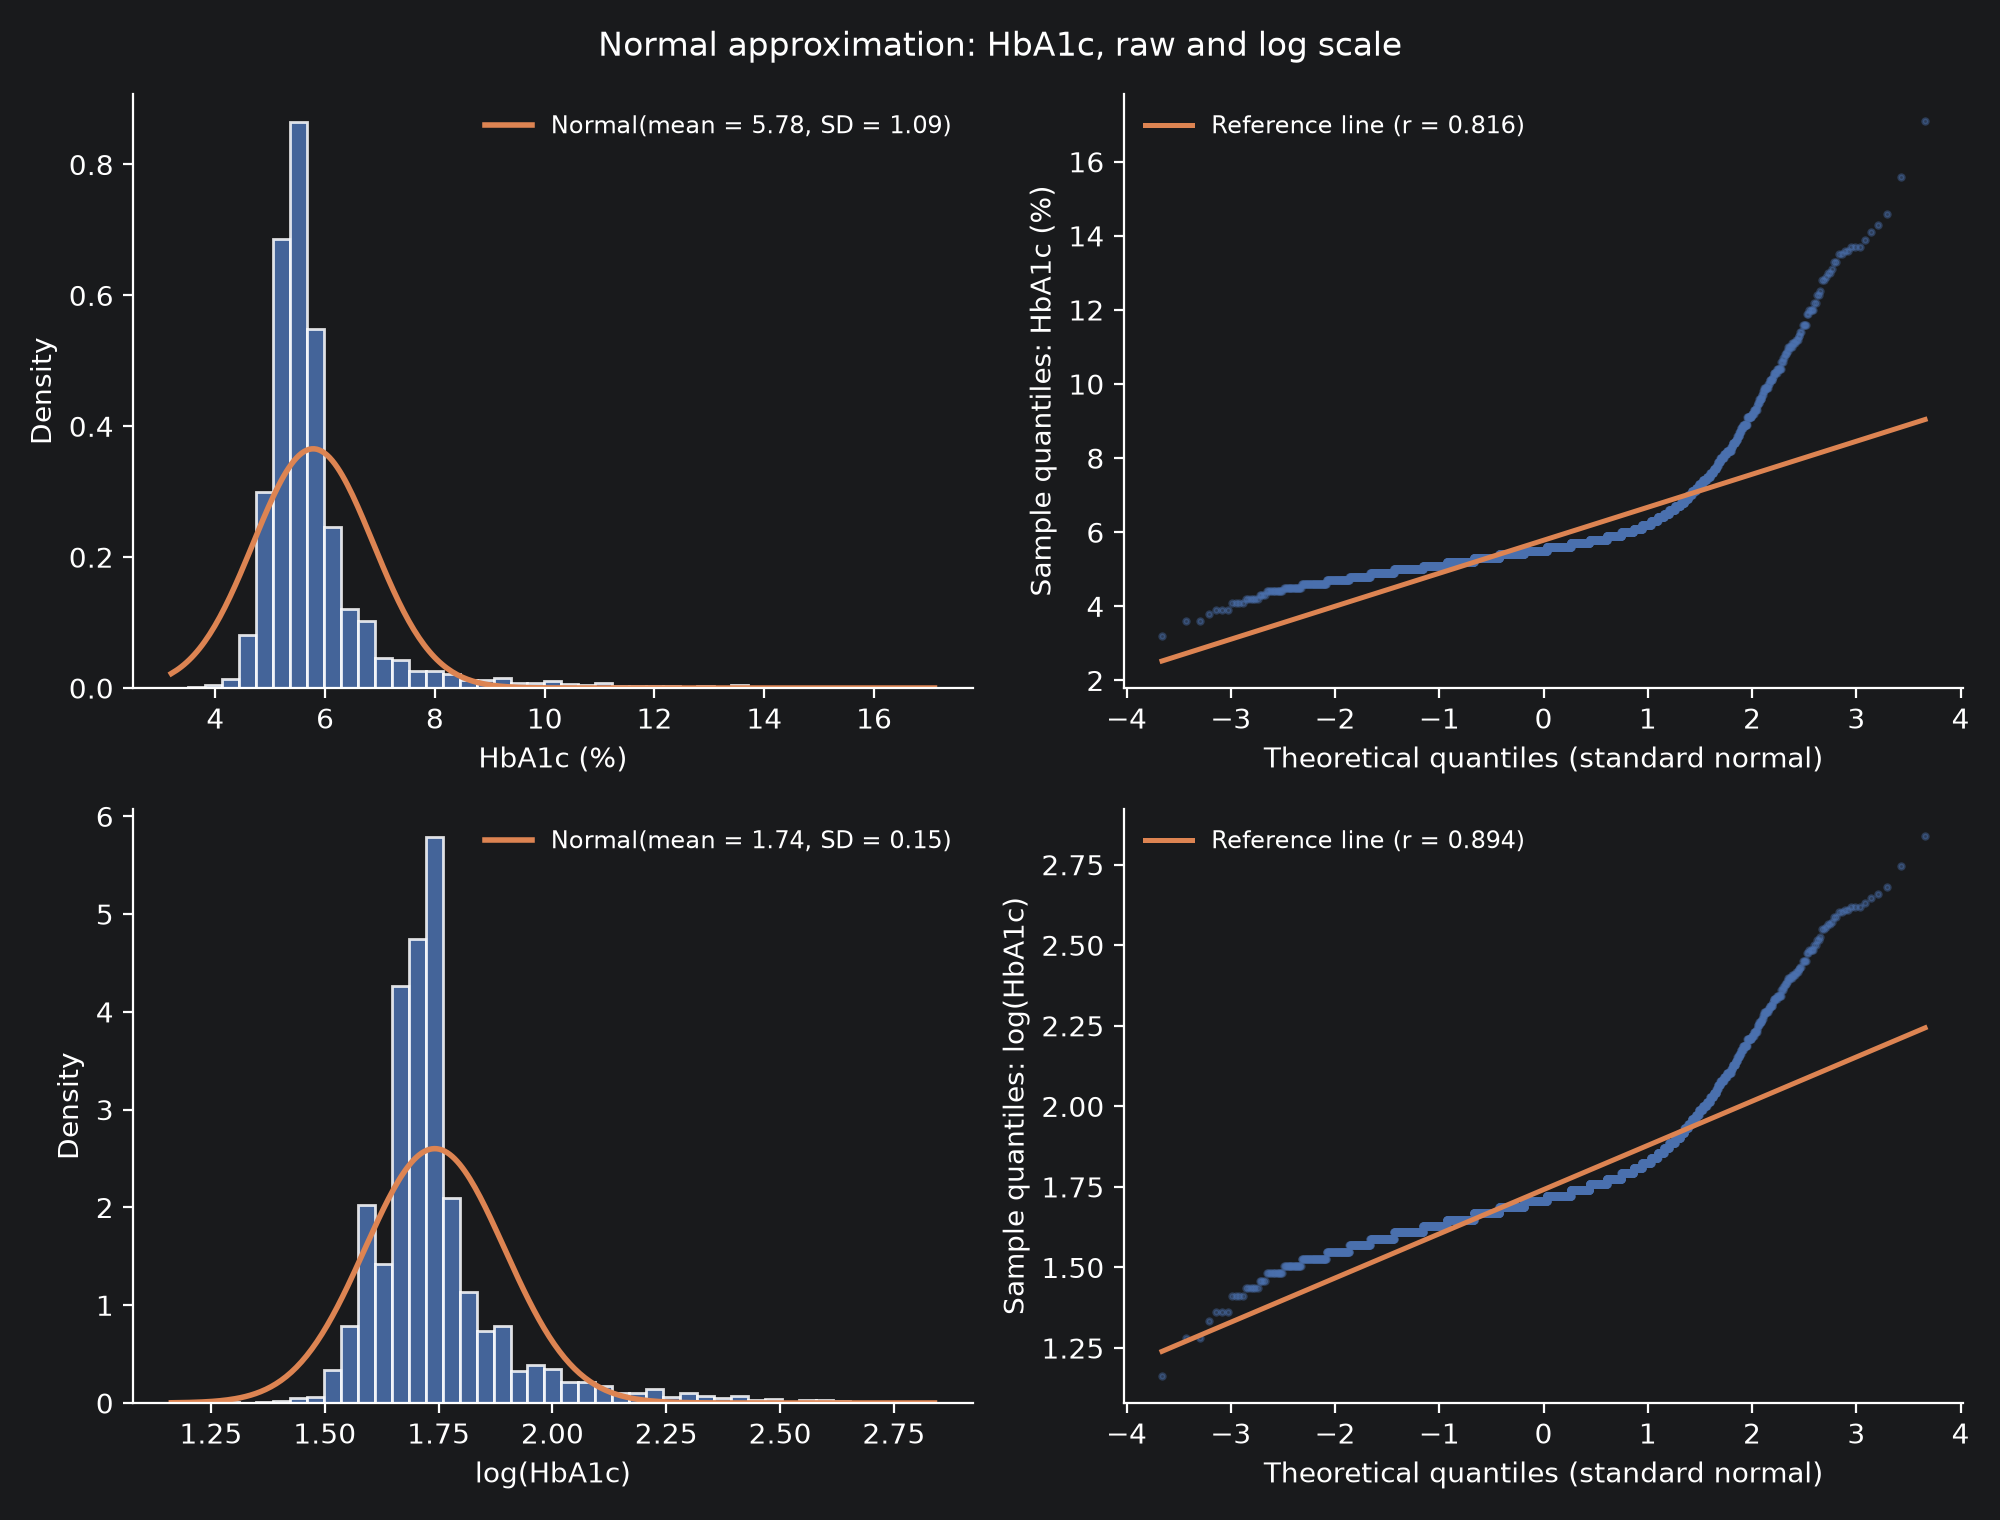

In [24]:
show_figure("p2_fig4_normal_sleep.png", width=720)
show_figure("p2_fig5_normal_bmi.png", width=720)
show_figure("p2_fig6_normal_hba1c.png", width=720)

**Interpretation.** Sleep is nearly symmetric but more peaked than a normal distribution (reported values are rounded to hours). BMI is right-skewed (1.23) but approximately normal on the log scale (skewness 0.44, Q-Q correlation 0.995). HbA1c is strongly right-skewed (3.56) with very heavy tails (139 values beyond 3 SD, all on the high side) and the log transformation does not fix this, so a normal model is not appropriate for HbA1c and the median and IQR remain the right summaries.

## 7. Expectation and variance (task 7)

In [25]:
show_table("expectation_variance")

,random_variable,unit,expectation,variance,sd,expectation_weighted,variance_weighted
0,I_B = 1 if HbA1c >= 6.5% (Bernoulli),probability,0.1242,0.1088,0.3299,0.1044,0.0935
1,K = number of I_B = 1 in 90 random adults (Bin...,adults,11.1803,9.7914,3.1291,9.4003,8.4185
2,HbA1c,%,5.7832,1.1910,1.0913,5.7067,1.1906
3,BMI,kg/m^2,29.8296,52.8539,7.2701,29.6955,52.5668
4,Sleep,h/day,7.8529,2.1528,1.4673,7.8643,1.9924


**Interpretation.** For the indicator I_B, E = P(B) = 0.1242 and Var = P(B)(1 − P(B)) = 0.1088. For the count K among 90 random adults, E(K) = 11.18 and Var(K) = 9.79 (SD 3.13). The average HbA1c is 5.78% (SD 1.09%, variance 1.19 %²). Weighted expectations estimate population quantities and are slightly lower because the weighted population is younger.

## 8. Two random variables and covariance (task 8)

,x,y,covariance,unit,direction
0,BMXBMI,LBXGH,1.6101,kg/m^2 x %,positive
1,sleep_hours,LBXGH,0.0437,h/day x %,positive
2,mvpa_min_week,LBXGH,-23.9052,min/week x %,negative
3,sedentary_hours,LBXGH,-0.0489,h/day x %,negative
4,sleep_hours,BMXBMI,-0.3971,h/day x kg/m^2,negative
5,mvpa_min_week,BMXBMI,-349.5636,min/week x kg/m^2,negative


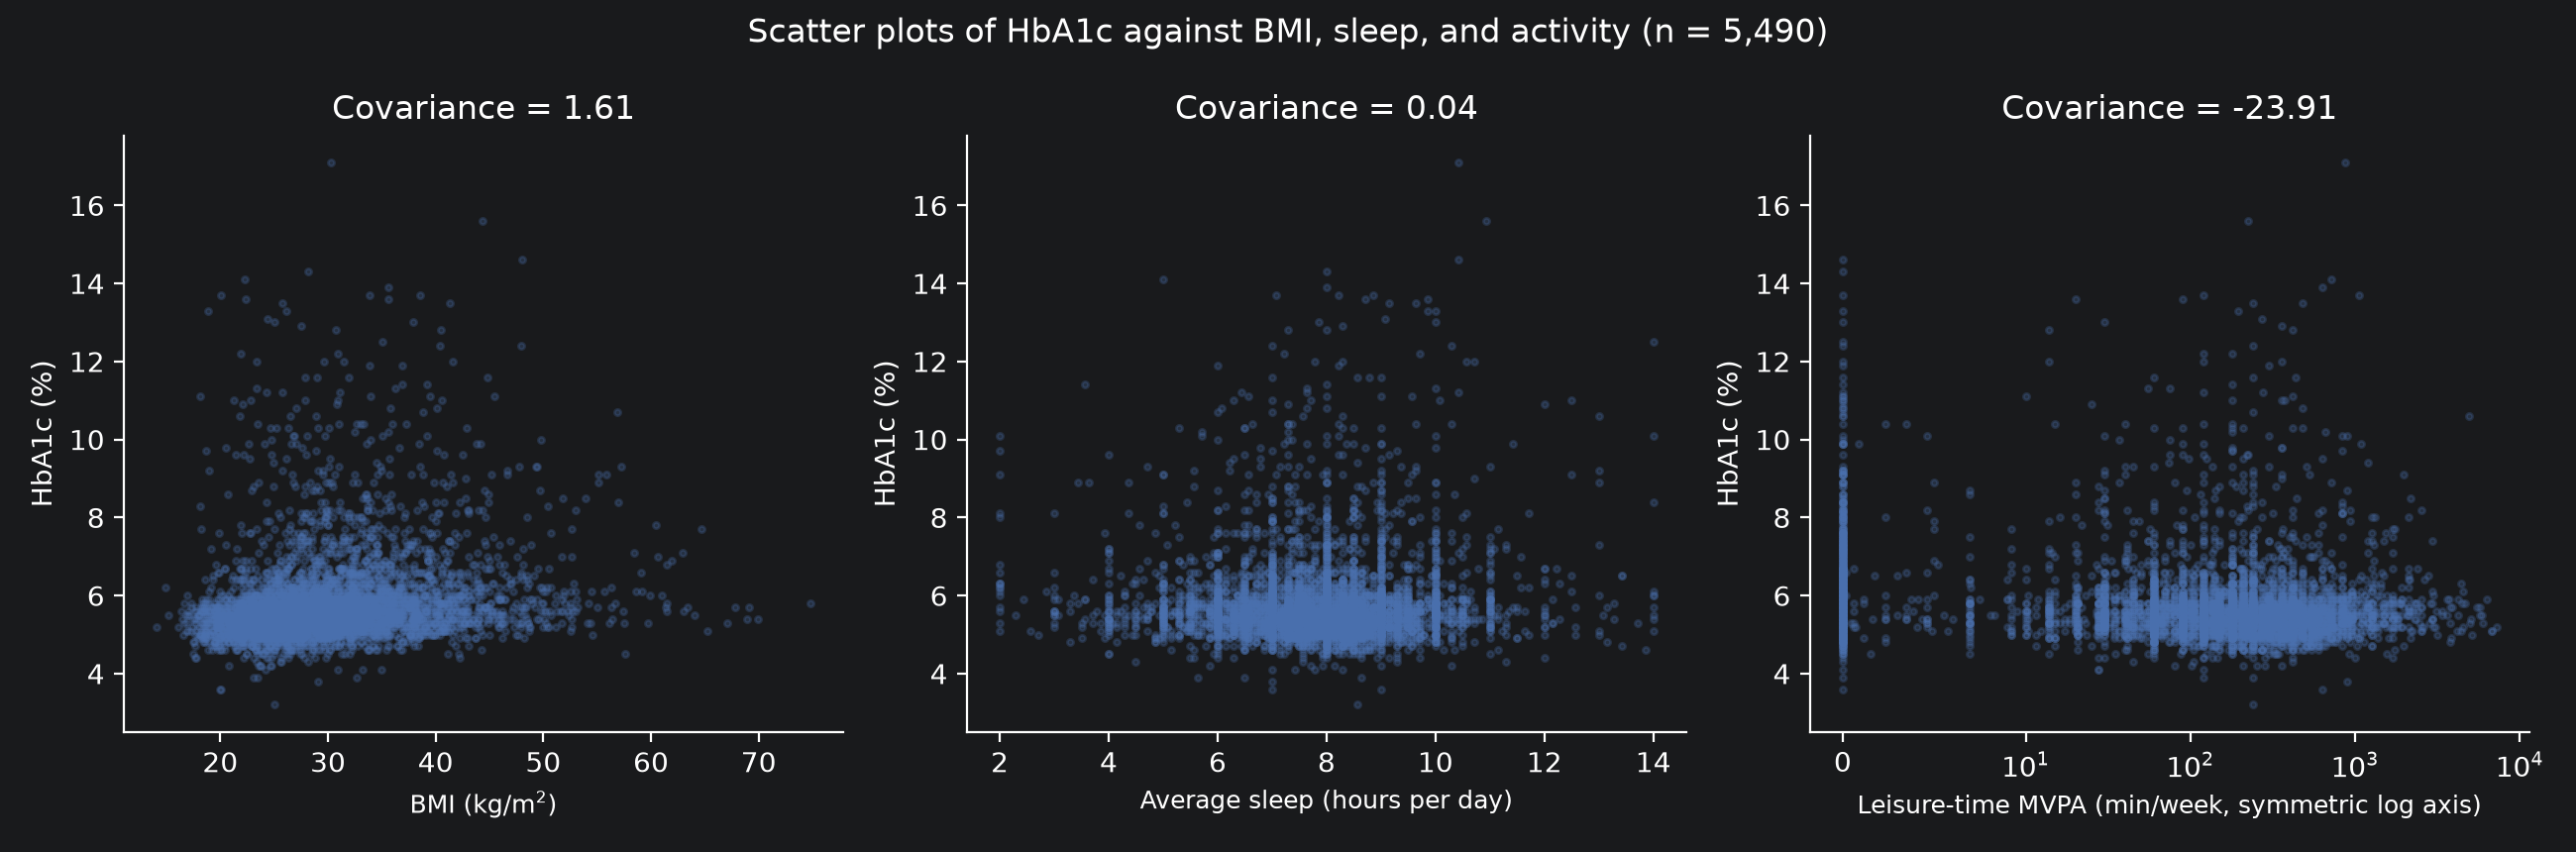

In [26]:
show_table("covariance_pairs")
show_figure("p2_fig7_scatter_covariance.png", width=860)

**Interpretation.** BMI and HbA1c have a positive covariance; leisure-time activity has a negative covariance with both HbA1c and BMI. The covariance of sleep and HbA1c is close to zero, consistent with the U-shaped pattern, because covariance measures only linear co-movement. Covariances depend on the units, so their sizes are not comparable across pairs (correlation is studied in Phase 4), and none of these relationships is causal.

## 9. Bayes' theorem (task 9)

Let D be a self-reported diabetes diagnosis. Participants with borderline diabetes are excluded from this calculation.

P(D | B) = P(B | D) P(D) / [P(B | D) P(D) + P(B | not D) P(not D)]

In [27]:
show_table("bayes_diabetes")

,version,n,P(D) prior,P(B|D),P(B|not D),P(B) total probability,P(D|B) by Bayes,P(D|B) direct,"P(not D|B), i.e. high HbA1c without diagnosis"
0,unweighted,5288,0.1452,0.6953,0.0250,0.1224,0.8253,0.8253,0.1747
1,weighted,5288,0.1190,0.7044,0.0209,0.1022,0.8199,0.8199,0.1801


**Interpretation.** With prior P(D) = 14.5%, P(B | D) = 69.5%, and P(B | not D) = 2.5%, Bayes' theorem gives P(D | B) = 82.5%, which equals the directly computed proportion. About 17.5% of adults with a diabetes-range HbA1c report no diagnosis. This describes agreement between two imperfect indicators, not the prevalence of undiagnosed diabetes.

## 10. Role of the sampling weights in empirical probability (A.4)

,quantity,unweighted,weighted
0,P(B) overall,0.1242,0.1044
1,P(B | age 20-39),0.0286,0.0300
2,P(B | age 40-59),0.1267,0.1181
3,P(B | age 60+),0.1745,0.1734
4,P(B | short sleep),0.1382,0.1192
5,P(short sleep),0.2016,0.1929
6,P(B) standardized to the weighted age distribu...,0.1072,0.1044


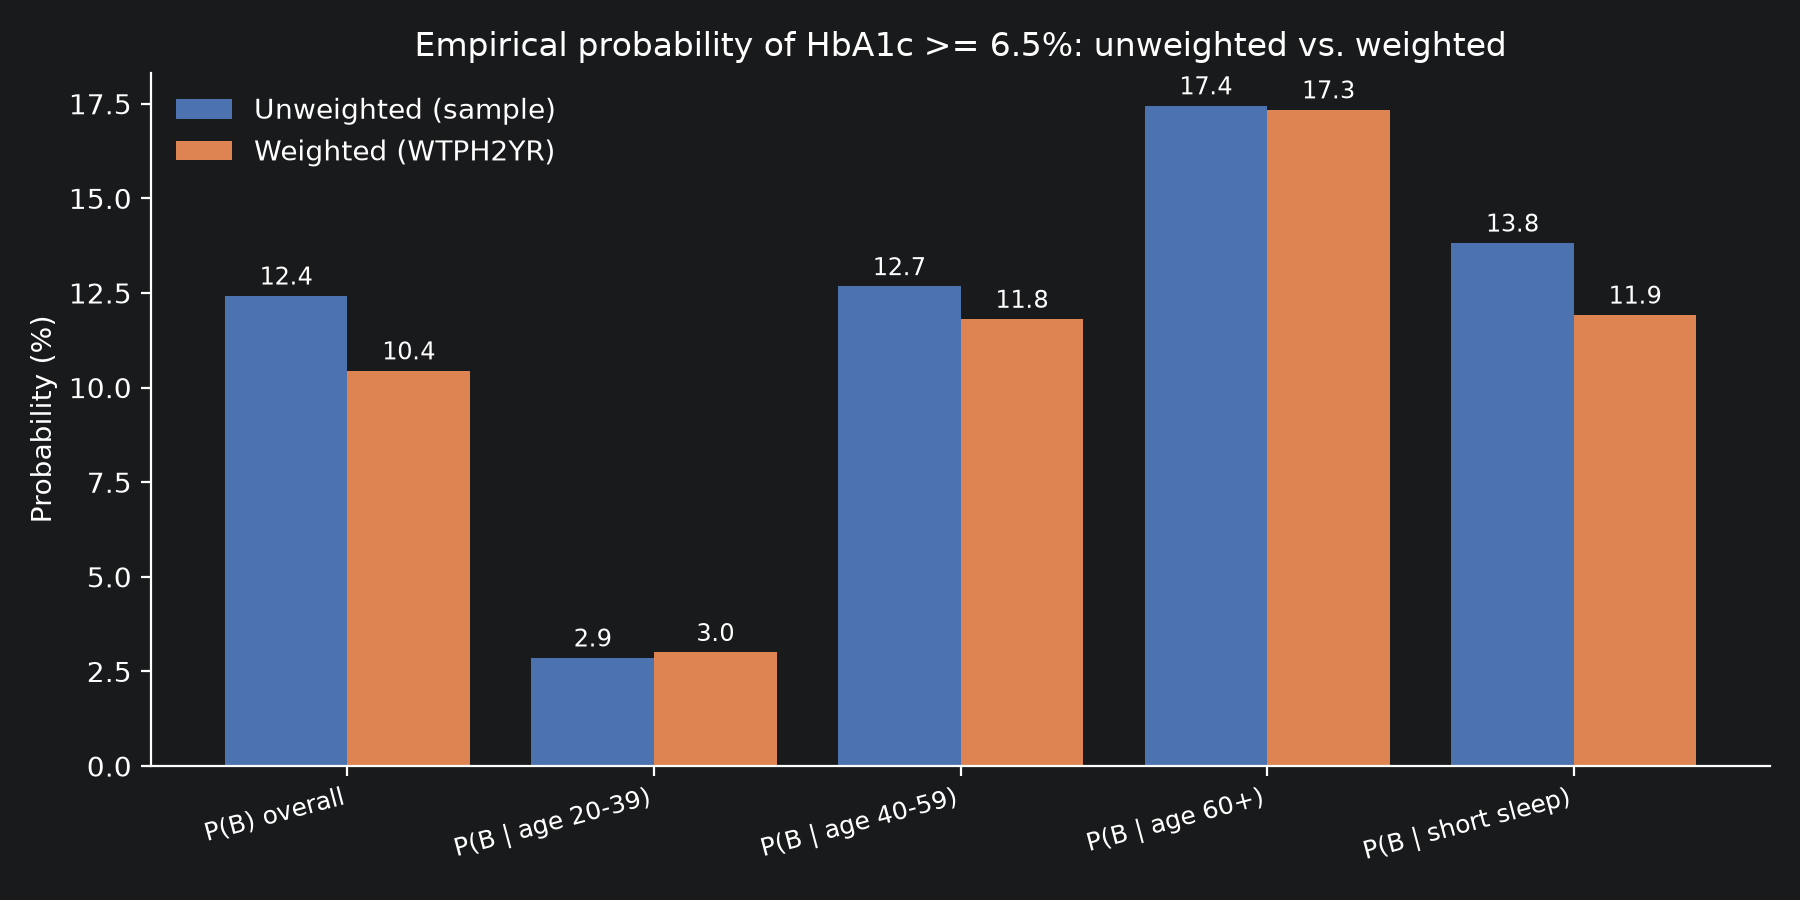

In [28]:
show_table("weights_effect_probabilities")
show_figure("p2_fig2_weighted_vs_unweighted.png", width=760)

**Interpretation.** The sample frequency of B is 12.4%, but the weighted estimate of the population probability is 10.4%. Older adults were oversampled and have a higher probability of B, so the sample overstates it. The age-specific probabilities change little with weighting; applying the weighted age distribution to the sample's age-specific probabilities gives 10.7%, close to the weighted 10.4%. A frequency in the sample is therefore not automatically an estimate of a population probability.

**Next.** Phase 3 moves from description to inference: sampling distributions, confidence intervals, bootstrap, and hypothesis tests.